# CCEP baseline expansion

All 117 ds004080 runs screened under the frozen pilot preprocessing. One 32-second clean interval is sufficient; up to three per run. [Protocol and exclusions](../notes/ccep-cohort-261014.md). Participants are the independent units.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').is_file() and (p/'research/empirical/ccep_pilot').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from research.empirical.ccep_pilot.plots import style, save, cohort_native_zoom
RUN=ROOT/'results/ccep-cohort-261014'
CONFIG=ROOT/'research/empirical/ccep_pilot/configs'
reports=json.loads((RUN/'scope/runs.json').read_text())
review=json.loads((CONFIG/'cohort-review.json').read_text())
screen=json.loads((CONFIG/'cohort-screen.json').read_text())
rows=[]
for r in reports:
    decisions=review['runs'][r['run_id']]
    rows.append(dict(participant=r['subject'][-2:],run=r['run_id'].split('run-')[-1],M=r['M'],native_Hz=r['native_fs'],
                     before_stimulation_s=round(r['first_stimulation'],1),retained=sum(v['accept'] for v in decisions.values()),
                     candidate=len(r['windows']),duplicate=r['run_id'] in review['duplicate_of']))
dimensions=pd.DataFrame(rows)
display(pd.DataFrame({'quantity':['Runs screened','Metadata candidates','Unique represented runs including pilot','Independent participants','New CAR windows','New reference controls','Pilot tables reused'],
                      'n':[len(screen),sum(bool(r['starts']) for r in screen),34,24,int(dimensions.retained.sum()),int((dimensions.retained>0).sum()),19]}))

,quantity,n
0,Runs screened,117
1,Metadata candidates,35
2,Unique represented runs including pilot,34
3,Independent participants,24
4,New CAR windows,54
5,New reference controls,29
6,Pilot tables reused,19


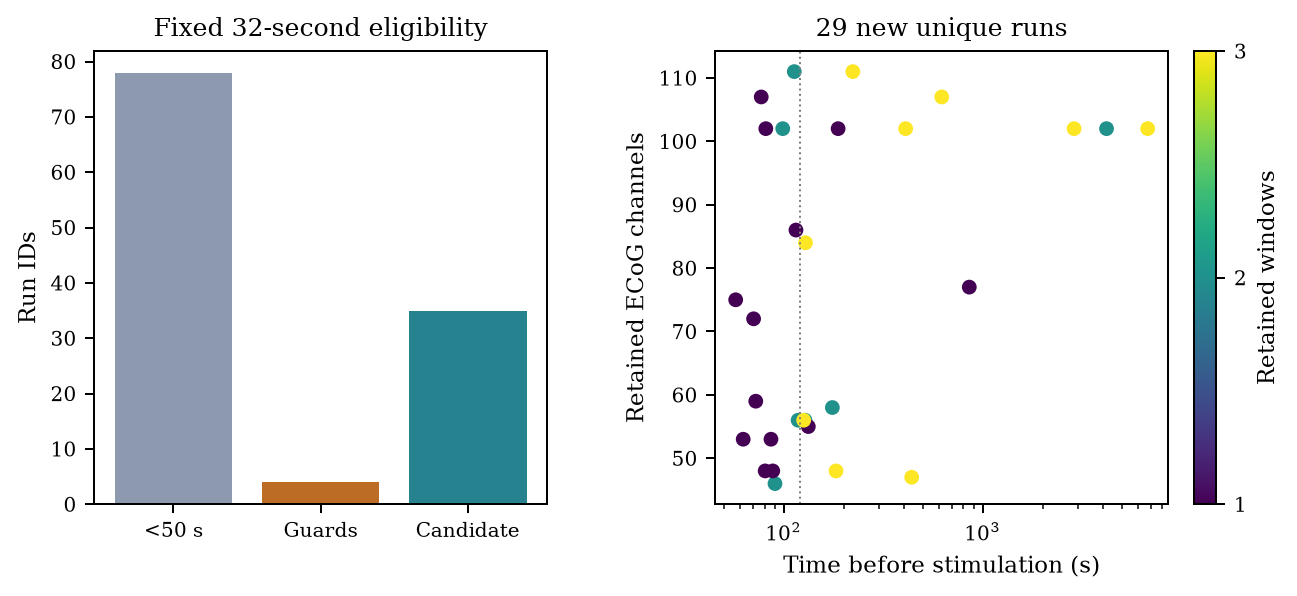

,participant,run,M,native_Hz,before_stimulation_s,retained,candidate,duplicate
0,01,021448,102,512,2877.9,3,3,False
1,01,031422,102,512,409.8,3,3,False
2,01,041224,102,512,4189.3,2,3,False
3,01,041550,102,512,6745.0,3,3,False
4,01,041750,102,512,187.5,1,2,False
5,01,061233,102,2048,98.8,2,2,False
6,01,061343,102,2048,81.2,1,1,False
7,02,021804,86,2048,115.1,1,2,False
8,03,031411,72,2048,70.5,1,1,False
9,04,031148,111,2048,112.9,2,2,False


In [2]:
plt=style()
fig,axes=plt.subplots(1,2,figsize=(7.2,3.2))
axes[0].bar(['<50 s','Guards','Candidate'],[78,4,35],color=['#8d99ae','#bc6c25','#26828e'])
axes[0].set(ylabel='Run IDs',title='Fixed 32-second eligibility')
active=dimensions[~dimensions.duplicate]
sc=axes[1].scatter(active.before_stimulation_s,active.M,c=active.retained,vmin=1,vmax=3,cmap='viridis',s=24)
axes[1].set(xscale='log',xlabel='Time before stimulation (s)',ylabel='Retained ECoG channels',title='29 new unique runs')
axes[1].axvline(120,color='.5',ls=':',lw=.8)
fig.colorbar(sc,ax=axes[1],ticks=[1,2,3],label='Retained windows')
for ax in axes: ax.set_box_aspect(1)
save(fig,RUN/'figures','cohort-scope')
display(Image(filename=str(RUN/'figures/cohort-scope.png')))
display(dimensions)

All 63 new candidate windows passed numerical QC. Native review excludes seven intervals with isolated slow excursions or few-sample impulses. Participant56/run021112 is an exact duplicate of run011112 (raw EEG, metadata/events and prepared arrays): compute once. Final new set: **54 CAR windows + 29 matched reference controls = 83 tables**, M=46–111, T=4096, 128 Hz, 0.5–45 Hz. Reference controls use each run’s first accepted interval.

,run,window,reason
0,sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-041224,0,Isolated sT2 slow excursion/tail occupies the ...
1,sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-041750,1,Two isolated sT2 slow excursions around 5 s an...
2,sub-ccepAgeUMCU02_ses-1_task-SPESclin_run-021804,0,Isolated F05 slow excursion/recovery across th...
3,sub-ccepAgeUMCU26_ses-1_task-SPESclin_run-011555,0,Isolated F08 slow excursion around 4–6 s domin...
4,sub-ccepAgeUMCU27_ses-1_task-SPESclin_run-031551,1,Isolated C04 slow excursion/recovery around 24...
5,sub-ccepAgeUMCU32_ses-1_task-SPESclin_run-031446,0,Native zoom resolves a few-sample impulsive di...
6,sub-ccepAgeUMCU32_ses-1_task-SPESclin_run-031446,1,Native zoom resolves a few-sample impulsive di...


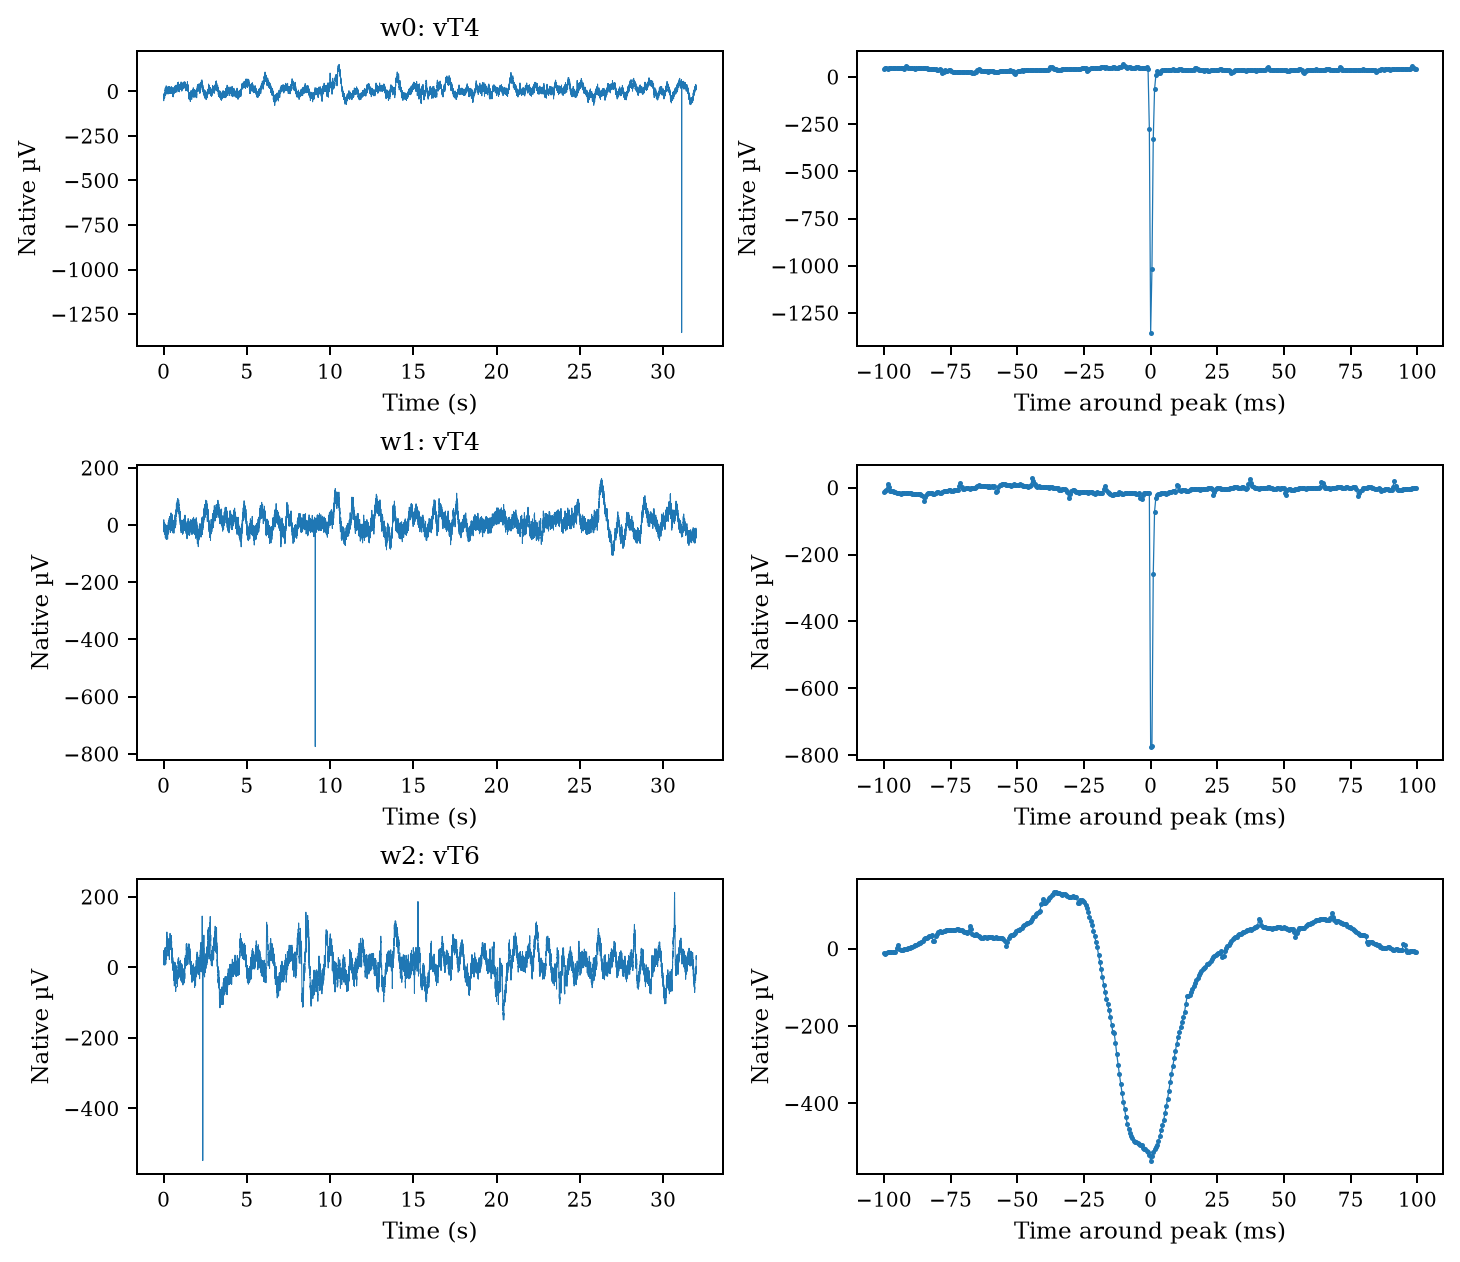

In [3]:
excluded=[]
for run,decisions in review['runs'].items():
    if run in review['duplicate_of']: continue
    for window,d in decisions.items():
        if not d['accept']: excluded.append(dict(run=run,window=int(window),reason=d['reason']))
display(pd.DataFrame(excluded))
cohort_native_zoom(RUN,'sub-ccepAgeUMCU32_ses-1_task-SPESclin_run-031446','32-native-zoom',.1)
display(Image(filename=str(RUN/'figures/32-native-zoom.png')))

The first two participant32 intervals contain very brief impulsive discontinuities; the third is retained. Resolved recurrent sharp/bursty activity is not automatically discarded or assigned a clinical origin. Sensitivity flags—including participant20/F41 activity and modest/shared slow excursions—remain in the explicit review. Retained intervals are not certified artefact-free.

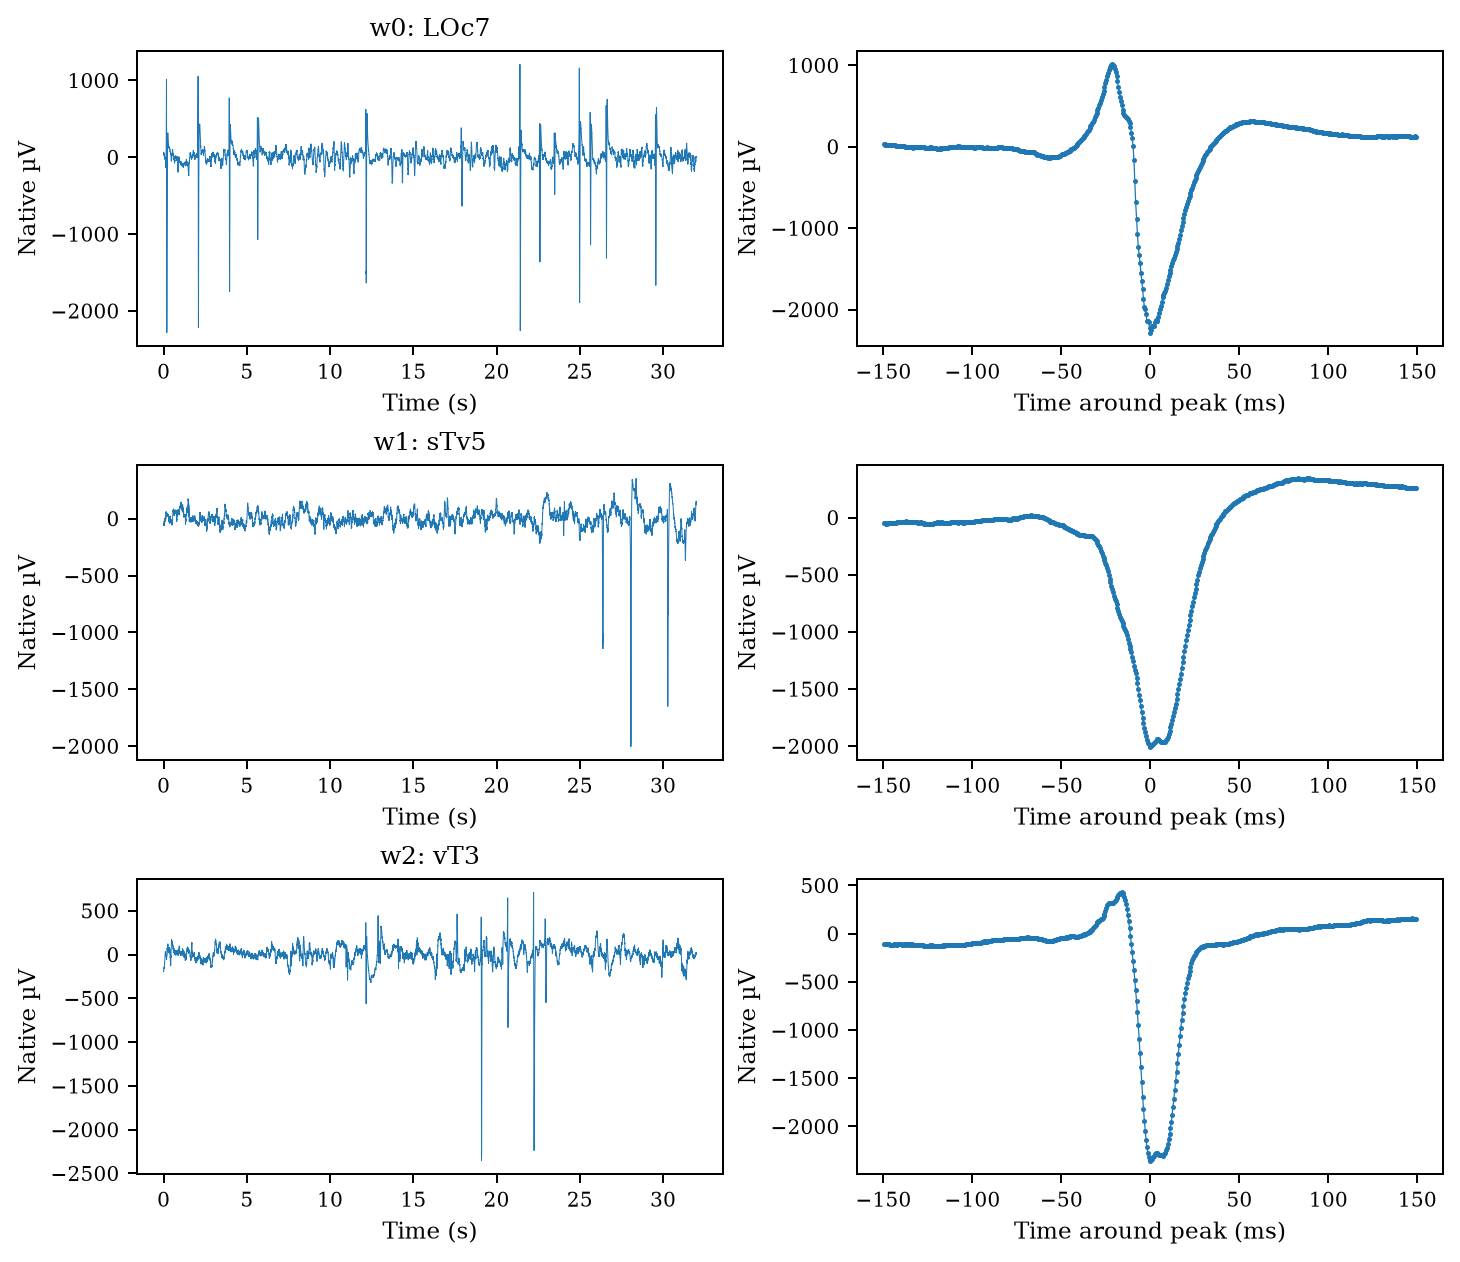

In [4]:
cohort_native_zoom(RUN,'sub-ccepAgeUMCU07_ses-1_task-SPESclin_run-021647','07-native-zoom',.15)
display(Image(filename=str(RUN/'figures/07-native-zoom.png')))

Full p90 uses frozen fd0de71/r9, full edges and fixed 8/12 workers. At 14 October 06:12 UTC: 38/83 tables validated, 17/22 measurements complete, ten farms running on 172 cores; 53 tables submitted and 30 owned by dependent release controllers. No cohort farm failure observed; audit 181238119 passed with 95.70–97.42% finite edges and no invalid outputs. Memory uses completed PBS peak ×1.25 and exact active cores. The separate pilot reference-control memory failure shows a CAR window may underestimate control memory. SPI–SPI interpretations and evoked-response comparisons remain pending.